# Freight rate prediction — concise solution
Predict **total posted rate in dollars** for every one of the 12,000 final loads. This notebook explains the data, validation, experiments, final model, and required December chart.

**Final model:** core CatBoost, RMSE loss, 425 trees; neither `market_index` nor `quote_signal` is used. The same estimator produces both required outputs.

**Execution:** Run all cells in order. Data checks, EDA, chronological baselines, metric calculations, and saved-model inference run fresh. Expensive historical experiments use **recorded predictions**, explicitly labeled below. Their complete code remains in [the original experiment notebook](freight_rate_prediction.ipynb). Optional retraining is disabled by default. A GPU is unnecessary for the default run.

**Colab setup:** Extract the complete `freight_submission` package into `/content`, then open this notebook. Uploading only the notebook is insufficient: it uses `solution.py`, `data/`, `outputs/`, the model, and configuration. Alternatively mount Drive and set `PROJECT_ROOT` below. Set `INSTALL_DEPENDENCIES = True` on the first run in a new environment; restart the runtime if Colab requests it.


In [1]:
from pathlib import Path
import importlib.util
import json
import subprocess
import sys

PROJECT_ROOT = None  # Or Path('/content/drive/MyDrive/freight_submission')
INSTALL_DEPENDENCIES = False  # True for a new Colab runtime without installed requirements
# For Drive, uncomment before resolving PROJECT_ROOT:
# from google.colab import drive
# drive.mount('/content/drive')

if PROJECT_ROOT is None:
    bases = [Path.cwd(), *Path.cwd().parents, Path('/content')]
    candidates = [p.resolve() for base in bases for p in (base, base / 'freight_submission')
                  if (p / 'solution.py').is_file() and (p / 'model_config.json').is_file()]
    candidates = list(dict.fromkeys(candidates))
    if len(candidates) != 1:
        raise ValueError(f'Set PROJECT_ROOT to the extracted package folder. Found: {candidates}')
    PROJECT_ROOT = candidates[0]
PROJECT_ROOT = Path(PROJECT_ROOT).expanduser().resolve()
assert (PROJECT_ROOT / 'solution.py').is_file(), 'PROJECT_ROOT must contain solution.py'
if INSTALL_DEPENDENCIES:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r',
                    str(PROJECT_ROOT / 'requirements.txt')], check=True)
print('Project:', PROJECT_ROOT)


Project: /home/ajeet/Downloads/Assigment/freight_submission


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor
from IPython.display import display, Image

# Load this project's module explicitly, avoiding an unrelated module named solution.
spec = importlib.util.spec_from_file_location('freight_solution', PROJECT_ROOT / 'solution.py')
solution = importlib.util.module_from_spec(spec)
spec.loader.exec_module(solution)
TARGET = solution.TARGET
RECORDED = PROJECT_ROOT / 'outputs'
RUN_DIR = PROJECT_ROOT / 'notebook_results'
RUN_DIR.mkdir(exist_ok=True)
config = json.loads((PROJECT_ROOT / 'model_config.json').read_text())
inputs = solution.load_inputs(PROJECT_ROOT)
raw_train, raw_final = inputs['train'], inputs['inference']
template, raw_december = inputs['template'], inputs['december']
pd.set_option('display.max_columns', 20)


## 1. Inspect all rows and check the input contract
The development data contains January–October 2025 labeled loads. November–December loads have no target. Inputs describe origin/destination, coordinates, distance, equipment, weight, date, and two candidate market signals. `load_id` is an identifier, never a model feature.

Checks and summaries below scan **every row**. Invalid weights are addressed in preprocessing; targets and unusual but valid rates are retained.


In [3]:
assert len(raw_train) == 48000 and len(raw_final) == len(template) == 12000
assert len(raw_december) == 31
assert list(template.columns) == ['load_id', 'predicted_rate']
required = set(solution.CORE_COLUMNS) - {'weight_was_missing', 'weight_was_invalid'}
required |= {'load_id', 'date', 'market_index', 'quote_signal'}
for frame in [raw_train, raw_final]:
    assert required <= set(frame.columns)
    assert frame['load_id'].notna().all() and frame['load_id'].is_unique
assert TARGET in raw_train and TARGET not in raw_final
assert template['load_id'].is_unique and template['load_id'].notna().all()
assert set(raw_final['load_id']) == set(template['load_id'])
assert set(raw_final['load_id']) == {f'TE-{i:06d}' for i in range(1, 12001)}
assert set(raw_train['load_id']).isdisjoint(raw_final['load_id'])
coverage, quality = [], []
for name, frame in [('development', raw_train), ('final_unlabeled', raw_final)]:
    dates = pd.to_datetime(frame['date'], format='%Y-%m-%d', errors='raise')
    assert dates.notna().all()
    coverage.append({'dataset': name, 'rows': len(frame), 'first_date': dates.min().date(),
                     'last_date': dates.max().date()})
    for column in ['distance', 'weight', 'market_index', 'quote_signal']:
        values = pd.to_numeric(frame[column], errors='raise')
        quality.append({'dataset': name, 'column': column, 'missing': values.isna().sum(),
                        'nonpositive': values.le(0).sum(), 'infinite': np.isinf(values).sum()})
display(pd.DataFrame(coverage))
display(pd.DataFrame(quality))


,dataset,rows,first_date,last_date
0,development,48000,2025-01-01,2025-10-31
1,final_unlabeled,12000,2025-11-01,2025-12-31


,dataset,column,missing,nonpositive,infinite
0,development,distance,0,0,0
1,development,weight,300,292,0
2,development,market_index,374,0,0
3,development,quote_signal,0,0,0
4,final_unlabeled,distance,0,0,0
5,final_unlabeled,weight,165,145,0
6,final_unlabeled,market_index,249,0,0
7,final_unlabeled,quote_signal,0,0,0


## 2. Clean consistently and explore the useful relationships
`solution.clean()` preserves every load and target. It parses dates/numerics, normalizes categorical blanks, flags missing/nonpositive weights, and replaces nonpositive weights with missing values. CatBoost handles missing numerical values directly. These rules do not learn anything from evaluation labels.

Distance and equipment provide useful pricing structure. Market/quote relationships can change over time, so random splitting would not represent the future prediction task well. Correlations are descriptive evidence, not proof of leakage or causation.


In [4]:
train = solution.clean(raw_train)
final_loads = solution.clean(raw_final)
assert train['load_id'].equals(raw_train['load_id'])
assert final_loads['load_id'].equals(raw_final['load_id'])
np.testing.assert_array_equal(train[TARGET], raw_train[TARGET])
assert train['date'].between('2025-01-01', '2025-10-31').all()
assert final_loads['date'].between('2025-11-01', '2025-12-31').all()
assert train['date'].max() < final_loads['date'].min()

monthly = []
for month, part in train.groupby(train['date'].dt.to_period('M')):
    monthly.append({'month': str(month), 'loads': len(part), 'median_rate': part[TARGET].median(),
                    'quote_target_correlation': part['quote_signal'].corr(part[TARGET]),
                    'market_target_correlation': part['market_index'].corr(part[TARGET])})
display(pd.DataFrame(monthly).round(3))
display(train.groupby('equipment').agg(loads=(TARGET, 'size'),
    median_distance=('distance', 'median'), median_rate=(TARGET, 'median')).round(2))
known_cities = set(train['pickup']) | set(train['delivery'])
known_lanes = set(zip(train['pickup'], train['delivery']))
unseen_city = ~final_loads['pickup'].isin(known_cities) | ~final_loads['delivery'].isin(known_cities)
unseen_lane = [(a, b) not in known_lanes for a, b in zip(final_loads['pickup'], final_loads['delivery'])]
print(f'Final loads with unseen city: {unseen_city.sum():,}; unseen directed lane: {sum(unseen_lane):,}')


,month,loads,median_rate,quote_target_correlation,market_target_correlation
0,2025-01,4918,1915.200,-0.600,0.013
1,2025-02,4337,1994.250,-0.639,0.007
2,2025-03,5036,2022.920,-0.595,0.012
3,2025-04,4819,2044.240,0.613,0.032
4,2025-05,4913,2065.510,0.624,0.001
5,2025-06,4783,2120.220,-0.580,0.008
6,2025-07,4912,2059.145,0.603,0.037
7,2025-08,4759,2015.730,0.015,0.003
8,2025-09,4670,2057.130,-0.591,0.011
9,2025-10,4853,2035.900,0.605,0.035


,loads,median_distance,median_rate
equipment,,,
Dry Van,27202,957.55,1953.04
Flatbed,8753,940.00,2076.81
Reefer,12045,950.20,2196.67


Final loads with unseen city: 1,447; unseen directed lane: 1,461


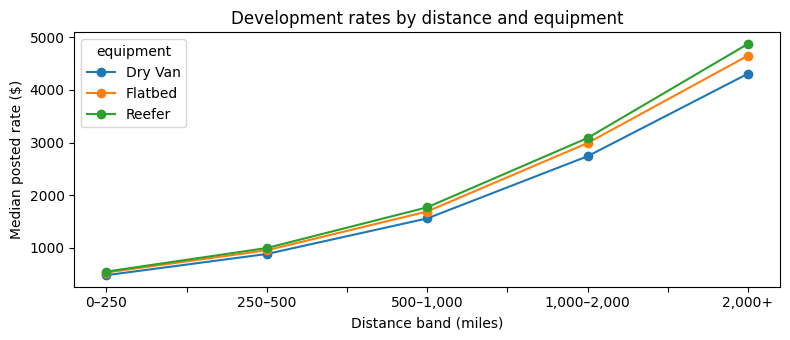

In [5]:
# Aggregate all development rows; no evaluation data is used to fit a model here.
bands = pd.cut(train['distance'], [0, 250, 500, 1000, 2000, np.inf],
               labels=['0–250', '250–500', '500–1,000', '1,000–2,000', '2,000+'])
pricing = train.groupby([bands, 'equipment'], observed=True)[TARGET].median().unstack()
ax = pricing.plot(marker='o', figsize=(8, 3.5), title='Development rates by distance and equipment')
ax.set(xlabel='Distance band (miles)', ylabel='Median posted rate ($)')
plt.tight_layout()
plt.show()


## 3. Chronological validation and evaluation metrics
Three expanding development folds evaluate March–August. The later January–August → September–October comparison subsequently **influenced the final model choice**, so it is not an independent final test. Some exploratory analysis also profiled the full development data. Hidden November–December accuracy remains unavailable.

For CatBoost experiments, the last **14 calendar days inside each training window** select the tree count (maximum 2,000, patience 100). Then the model is refitted on that entire training window and evaluated on the later outer window. The outer evaluation labels are not used for early stopping.

MAE measures typical dollar error; RMSE emphasizes large misses; WAPE is total absolute error divided by total actual rate, as a percentage. Bias is mean predicted minus actual rate; negative means underprediction. MAE, RMSE, and bias are in dollars; WAPE is not. Pooled metrics use all predictions, not an unweighted average of fold scores.


In [6]:
FOLD_SPECS = [
    ('fold_A', '2025-02-28', '2025-03-01', '2025-04-30'),
    ('fold_B', '2025-04-30', '2025-05-01', '2025-06-30'),
    ('fold_C', '2025-06-30', '2025-07-01', '2025-08-31'),
    ('later_comparison', '2025-08-31', '2025-09-01', '2025-10-31'),
]
folds, fold_rows = {}, []
for name, end, start_eval, end_eval in FOLD_SPECS:
    fitting = train.loc[train['date'].le(end)]
    evaluation = train.loc[train['date'].between(start_eval, end_eval)]
    assert len(fitting) and len(evaluation)
    assert fitting['date'].max() < evaluation['date'].min()
    assert set(fitting['load_id']).isdisjoint(evaluation['load_id'])
    folds[name] = (fitting, evaluation)
    fold_rows.append({'fold': name, 'train_through': end, 'evaluate_from': start_eval,
                      'evaluate_through': end_eval, 'train_rows': len(fitting), 'eval_rows': len(evaluation)})
display(pd.DataFrame(fold_rows))


,fold,train_through,evaluate_from,evaluate_through,train_rows,eval_rows
0,fold_A,2025-02-28,2025-03-01,2025-04-30,9255,9855
1,fold_B,2025-04-30,2025-05-01,2025-06-30,19110,9696
2,fold_C,2025-06-30,2025-07-01,2025-08-31,28806,9671
3,later_comparison,2025-08-31,2025-09-01,2025-10-31,38477,9523


## 4. Recompute simple baselines
The constant model uses the training median rate. The equipment/mileage baseline multiplies distance by the training median dollars per mile for that equipment; unseen equipment uses the global training median. Neither uses evaluation labels for fitting.


In [7]:
baseline_parts = []
for fold, (fitting, evaluation) in list(folds.items())[:3]:
    rpm = fitting[TARGET] / fitting['distance']
    equipment_rpm = rpm.groupby(fitting['equipment']).median()
    predictions = {
        'constant_median': np.full(len(evaluation), fitting[TARGET].median()),
        'equipment_mileage': evaluation['distance'] * evaluation['equipment'].map(equipment_rpm).fillna(rpm.median()),
    }
    for name, values in predictions.items():
        part = evaluation[['load_id', 'distance', TARGET]].rename(columns={TARGET: 'actual_rate'}).copy()
        part = part.assign(fold=fold, model=name, predicted_rate=np.asarray(values))
        assert np.isfinite(part['predicted_rate']).all() and part['predicted_rate'].gt(0).all()
        baseline_parts.append(part)
baseline_oof = pd.concat(baseline_parts, ignore_index=True)
assert not baseline_oof.duplicated(['model', 'load_id']).any()

def summarize_predictions(frame, groups):
    records = []
    for key, part in frame.groupby(groups, observed=True, sort=True):
        key = key if isinstance(key, tuple) else (key,)
        records.append(dict(zip(groups, key), evaluated_loads=len(part),
                            **solution.metrics(part['actual_rate'], part['predicted_rate'])))
    return pd.DataFrame(records)

display(summarize_predictions(baseline_oof, ['model']).round(2))


,model,evaluated_loads,MAE,RMSE,WAPE_pct,bias
0,constant_median,29222,1143.53,1557.16,47.59,-414.27
1,equipment_mileage,29222,206.56,626.69,8.60,-32.86


In [8]:
errors = baseline_oof.loc[baseline_oof['model'].eq('equipment_mileage')].copy()
errors['distance_band'] = pd.cut(errors['distance'], [0, 250, 500, 1000, 2000, np.inf],
    labels=['0–250', '250–500', '500–1,000', '1,000–2,000', '2,000+'])
display(summarize_predictions(errors, ['distance_band']).round(2))
absolute = (errors['predicted_rate'] - errors['actual_rate']).abs().sort_values(ascending=False)
k = int(np.ceil(len(absolute) * 0.01))
print(f'Largest {k} errors ({100*k/len(absolute):.2f}% of loads): '
      f'{100*absolute.iloc[:k].sum()/absolute.sum():.2f}% of absolute error, '
      f'{100*(absolute.iloc[:k]**2).sum()/(absolute**2).sum():.2f}% of squared error.')


,distance_band,evaluated_loads,MAE,RMSE,WAPE_pct,bias
0,0–250,1668,131.02,180.69,26.47,-127.59
1,250–500,4585,156.21,258.90,16.56,-149.15
2,"500–1,000",9163,151.88,410.65,9.03,-124.38
3,"1,000–2,000",9258,190.05,728.37,6.27,-30.83
4,"2,000+",4548,428.78,1012.01,9.03,299.40


Largest 293 errors (1.00% of loads): 23.08% of absolute error, 87.97% of squared error.


## 5. Compare recorded development experiments
The following metrics are recomputed from **saved out-of-fold predictions**, not freshly retrained models. Each saved label and evaluation ID is checked against the current data and splits. The original notebook retains the training code for every alternative.

| Experiment | Reason tested / outcome |
|---|---|
| Ridge / Huber | Interpretable linear alternatives; Huber reduces sensitivity to large residuals. Both improve the mileage baseline, but CatBoost improves MAE further. |
| Core CatBoost / market CatBoost | Capture nonlinear pricing and categorical interactions; adding market index helps the earlier folds. |
| Raw-dollar MAE CatBoost | Severely underfit with the observed GPU gradient configuration. This is an optimization failure, not evidence that MAE is generally unsuitable. |
| Scaled MAE plus market | Dividing training targets by 1,000 and restoring dollars improves optimization and wins the earlier development comparison. |
| Quote addition | Improves one fold but worsens two, and worsens pooled MAE; excluded. |

CatBoost accepts categorical inputs and numerical missing values without a large one-hot preprocessing pipeline. Core features and the final configuration are shown below. No untested model family is claimed to have been experimentally rejected.


In [9]:
recorded_files = ['linear_oof_predictions.csv', 'catboost_core_oof_predictions.csv',
    'catboost_market_oof_predictions.csv', 'catboost_market_mae_oof_predictions.csv',
    'catboost_market_mae_scaled_oof_predictions.csv']
parts = [baseline_oof]
truth = train.set_index('load_id')[TARGET]
for filename in recorded_files:
    part = pd.read_csv(RECORDED / filename)
    assert np.isfinite(part[['actual_rate', 'predicted_rate']].to_numpy()).all()
    assert not part.duplicated(['model', 'load_id']).any()
    assert set(part['fold']) == {'fold_A', 'fold_B', 'fold_C'}
    for (model_name, fold), group in part.groupby(['model', 'fold']):
        assert set(group['load_id']) == set(folds[fold][1]['load_id'])
    np.testing.assert_allclose(part['actual_rate'], part['load_id'].map(truth), rtol=0, atol=1e-8)
    parts.append(part)
development_predictions = pd.concat(parts, ignore_index=True)
assert not development_predictions.duplicated(['model', 'load_id']).any()
development_metrics = summarize_predictions(development_predictions, ['model']).sort_values('MAE')
print('Recorded experiments + freshly recomputed baselines:')
display(development_metrics.round(2))
display(summarize_predictions(development_predictions, ['fold', 'model'])
        .pivot(index='fold', columns='model', values='MAE').round(2))
development_metrics.to_csv(RUN_DIR / 'development_metrics.csv', index=False)


Recorded experiments + freshly recomputed baselines:


,model,evaluated_loads,MAE,RMSE,WAPE_pct,bias
3,catboost_market_mae_scaled,29222,115.27,602.42,4.80,-78.89
1,catboost_market,29222,125.98,605.85,5.24,-58.65
0,catboost_core,29222,148.80,612.77,6.19,-89.65
7,ridge,29222,166.69,616.69,6.94,-92.20
6,huber,29222,172.95,619.62,7.20,-115.28
5,equipment_mileage,29222,206.56,626.69,8.60,-32.86
2,catboost_market_mae,29222,1099.55,1522.70,45.76,-414.47
4,constant_median,29222,1143.53,1557.16,47.59,-414.27


model,catboost_core,catboost_market,catboost_market_mae,catboost_market_mae_scaled,constant_median,equipment_mileage,huber,ridge
fold,,,,,,,,
fold_A,147.31,131.10,1082.84,117.01,1126.74,191.06,169.33,160.70
fold_B,179.81,134.79,1132.43,119.83,1175.96,206.18,207.43,195.74
fold_C,119.24,111.92,1083.60,108.92,1128.11,222.73,142.06,143.66


In [10]:
print('Recorded quote ablation:')
display(pd.read_csv(RECORDED / 'quote_pooled_comparison.csv').round(2))
print('Recorded city stress test — MARKET / SCALED-MAE CANDIDATE ONLY:')
display(pd.read_csv(RECORDED / 'unfamiliar_city_stress_metrics.csv').round(2))


Recorded quote ablation:


,model,MAE,RMSE,WAPE_pct,bias
0,with_quote,125.09,605.09,5.21,-65.16
1,without_quote,115.27,602.42,4.80,-78.89


Recorded city stress test — MARKET / SCALED-MAE CANDIDATE ONLY:


,model,city_group,loads,MAE,RMSE,WAPE_pct,bias
0,mileage_reduced_training,other_cities,8206,210.07,613.11,9.25,36.25
1,mileage_reduced_training,withheld_city,1465,328.22,907.88,11.03,148.54
2,catboost_reduced_training,other_cities,8206,103.42,574.92,4.55,-69.87
3,catboost_reduced_training,withheld_city,1465,144.38,856.23,4.85,-88.43
4,catboost_original_training_reference,other_cities,8206,103.11,574.52,4.54,-68.87
5,catboost_original_training_reference,withheld_city,1465,141.49,856.93,4.75,-90.57


The withheld-city experiment shows that the **market/scaled-MAE candidate** remained useful when selected cities were excluded from fitting. These scores must not be attributed to the final core model, which was not subjected to that same stress test. The baseline tail analysis also explains why RMSE stays large despite improved MAE; unusual targets were retained rather than removed to improve scores.

## 6. Later-period comparison and final selection
The provisional market/MAE model degraded in September–October. The core/RMSE candidate performed better on that period and was selected for submission. Historical names below are mapped explicitly: `main_mae_market` is the **rejected candidate**; `chart_core_rmse` is the **selected core recipe**, used for both final-load predictions and the chart.

This change used the later-period results for selection. These numbers describe that comparison, not guaranteed future accuracy. There is no universal acceptable-error threshold without business costs and tolerances.


In [11]:
later = pd.read_csv(RECORDED / 'reserved_predictions.csv', parse_dates=['date'])
assert not later.duplicated(['model', 'load_id']).any()
for name, group in later.groupby('model'):
    assert set(group['load_id']) == set(folds['later_comparison'][1]['load_id'])
np.testing.assert_allclose(later['actual_rate'], later['load_id'].map(truth), rtol=0, atol=1e-8)
expected_dates = train.set_index('load_id')['date']
assert later['date'].equals(later['load_id'].map(expected_dates))
labels = {'main_mae_market': 'market_mae_candidate', 'chart_core_rmse': 'selected_core_rmse',
          'equipment_mileage': 'equipment_mileage'}
assert set(later['model']) == set(labels)
later['model'] = later['model'].map(labels)
later_metrics = summarize_predictions(later, ['model']).sort_values('MAE')
display(later_metrics.round(2))
selected = later.loc[later['model'].eq('selected_core_rmse')].copy()
selected['month'] = selected['date'].dt.strftime('%Y-%m')
print('Selected CORE model by month (corrected label and model):')
display(summarize_predictions(selected, ['month']).round(2))
later_metrics.to_csv(RUN_DIR / 'later_comparison_metrics.csv', index=False)


,model,evaluated_loads,MAE,RMSE,WAPE_pct,bias
2,selected_core_rmse,9523,110.39,631.00,4.61,-24.27
1,market_mae_candidate,9523,168.47,651.44,7.04,-145.16
0,equipment_mileage,9523,229.10,670.66,9.58,40.93


Selected CORE model by month (corrected label and model):


,month,evaluated_loads,MAE,RMSE,WAPE_pct,bias
0,2025-09,4670,109.37,614.15,4.55,-20.68
1,2025-10,4853,111.37,646.80,4.68,-27.72


## 7. Final recipe and optional retraining
The final model was refitted on all 48,000 labeled loads. An inner last-14-day split selected **425 trees** before that refit. Target scale is 1 (dollars); outputs are floored at $1 consistently with evaluation.

Only weekday is extracted from the date. Features exclude ID, target, market index, and quote. `solution.features()` and `solution.fit_recipe()` are shared by training and inference. The latter implements the inner chronological stopping and full-window refit described above.

The optional cell can rerun the core later-period evaluation and full-data training on Colab GPU (or CPU). It writes separate artifacts into `notebook_results/retraining/`. Subsequent submission cells deliberately use the archived model to reproduce the submitted predictions. GPU retraining is not bit-for-bit deterministic; CPU training can also differ. Reselecting tree count is optional; otherwise full-data retraining uses the recorded 425 trees.


In [12]:
assert config['target_scale'] == 1.0 and config['iterations'] == 425
assert config['parameters']['loss_function'] == 'RMSE'
assert list(solution.features(train.head()).columns) == config['features']
assert solution.CAT_COLUMNS == config['categorical_features']
assert not {'load_id', TARGET, 'quote_signal', 'market_index'} & set(config['features'])
display(pd.DataFrame({'feature': config['features'],
    'type': ['categorical' if c in solution.CAT_COLUMNS else 'numeric' for c in config['features']]}))
print(json.dumps(config['parameters'], indent=2))


,feature,type
0,pickup,categorical
1,delivery,categorical
2,equipment,categorical
3,pickup_lat,numeric
4,pickup_lon,numeric
5,delivery_lat,numeric
6,delivery_lon,numeric
7,distance,numeric
8,weight,numeric
9,weight_was_missing,numeric


{
  "task_type": "GPU",
  "devices": "0",
  "depth": 6,
  "learning_rate": 0.05,
  "l2_leaf_reg": 5,
  "loss_function": "RMSE",
  "eval_metric": "MAE",
  "random_seed": 42,
  "allow_writing_files": false
}


In [13]:
RUN_RETRAINING = False
TRAIN_TASK_TYPE = 'GPU'  # Set CPU if GPU training is unavailable.
RESELECT_FINAL_TREES = False
if RUN_RETRAINING:
    retraining_dir = RUN_DIR / 'retraining'
    retraining_dir.mkdir(exist_ok=True)
    params = dict(config['parameters'], task_type=TRAIN_TASK_TYPE)
    if TRAIN_TASK_TYPE == 'CPU':
        params.pop('devices', None)
    fitting, evaluation = folds['later_comparison']
    rerun = solution.fit_recipe(fitting, params)
    rerun_metrics = {'trees': rerun.tree_count_,
        **solution.metrics(evaluation[TARGET], solution.predict(rerun, evaluation))}
    display(pd.DataFrame([rerun_metrics]).round(2))
    pd.DataFrame([rerun_metrics]).to_csv(retraining_dir / 'core_later_metrics.csv', index=False)
    refit = solution.fit_recipe(train, params, None if RESELECT_FINAL_TREES else config['iterations'])
    refit.save_model(str(retraining_dir / 'retrained_core.cbm'))
    (retraining_dir / 'config.json').write_text(json.dumps({
        'parameters': params, 'iterations': refit.tree_count_, 'target_scale': 1.0,
        'features': config['features'], 'reselected_iterations': RESELECT_FINAL_TREES}, indent=2))
    print('Retrained artifacts:', retraining_dir)
else:
    print('Optional retraining skipped. Saved-model reproduction follows.')


Optional retraining skipped. Saved-model reproduction follows.


## 8. Predict every final load with the saved model
The prediction lookup is joined to the template by `load_id`, preserving template order. The original model and submission remain unchanged; regenerated files are written under `notebook_results/`.


In [14]:
model = CatBoostRegressor()
model.load_model(str(PROJECT_ROOT / 'artifacts' / 'final_model.cbm'))
assert model.tree_count_ == config['iterations']
assert model.feature_names_ == config['features']
lookup = pd.DataFrame({'load_id': final_loads['load_id'],
                       'predicted_rate': solution.predict(model, final_loads, config['target_scale'])})
submission = template[['load_id']].merge(lookup, on='load_id', how='left', sort=False, validate='one_to_one')
assert list(submission.columns) == ['load_id', 'predicted_rate']
assert len(submission) == 12000 and submission['load_id'].is_unique
assert submission['load_id'].equals(template['load_id'])
assert np.isfinite(submission['predicted_rate']).all() and submission['predicted_rate'].gt(0).all()
submission_path = RUN_DIR / 'validation_predictions.csv'
submission.to_csv(submission_path, index=False, float_format='%.6f')
print(f'Generated {len(submission):,} predictions using {model.tree_count_} trees.')


Generated 12,000 predictions using 425 trees.


## 9. Fixed December scenarios and reproduction checks
Coordinates for the fixed route come from the development city lookup only. The same final model predicts all 31 rows, with original scenario fields preserved. Both regenerated CSVs must reproduce the archived predictions within $0.000001, allowing six-decimal CSV rounding.


In [15]:
city_lookup = solution.coordinates(train)
december_features = solution.prepare_december(raw_december, city_lookup)
december = raw_december.copy()
december['predicted_rate'] = solution.predict(model, december_features, config['target_scale'])
assert december.drop(columns='predicted_rate').equals(raw_december.drop(columns='predicted_rate'))
december_path = RUN_DIR / 'december_predictions.csv'
december.to_csv(december_path, index=False, float_format='%.6f')

for generated, original, label in [
    (submission_path, PROJECT_ROOT / 'validation_predictions.csv', 'final loads'),
    (december_path, RECORDED / 'december_predictions.csv', 'December scenarios'),
]:
    current, saved = pd.read_csv(generated), pd.read_csv(original)
    assert list(current.columns) == list(saved.columns) and len(current) == len(saved)
    pd.testing.assert_frame_equal(current.drop(columns='predicted_rate'), saved.drop(columns='predicted_rate'))
    np.testing.assert_allclose(current['predicted_rate'], saved['predicted_rate'], rtol=0, atol=1e-6)
    difference = (current['predicted_rate'] - saved['predicted_rate']).abs().max()
    print(f'Verified {len(current):,} {label}; maximum saved-CSV difference ${difference:.9f}.')


Verified 12,000 final loads; maximum saved-CSV difference $0.000000000.
Verified 31 December scenarios; maximum saved-CSV difference $0.000000000.


## 10. Official scorer and required chart
The organizer's unchanged `score.py` checks submission format, IDs, positive finite rates, and the fixed December scenario. It does **not** calculate hidden-label accuracy.


Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: /home/ajeet/Downloads/Assigment/freight_submission/notebook_results/scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.



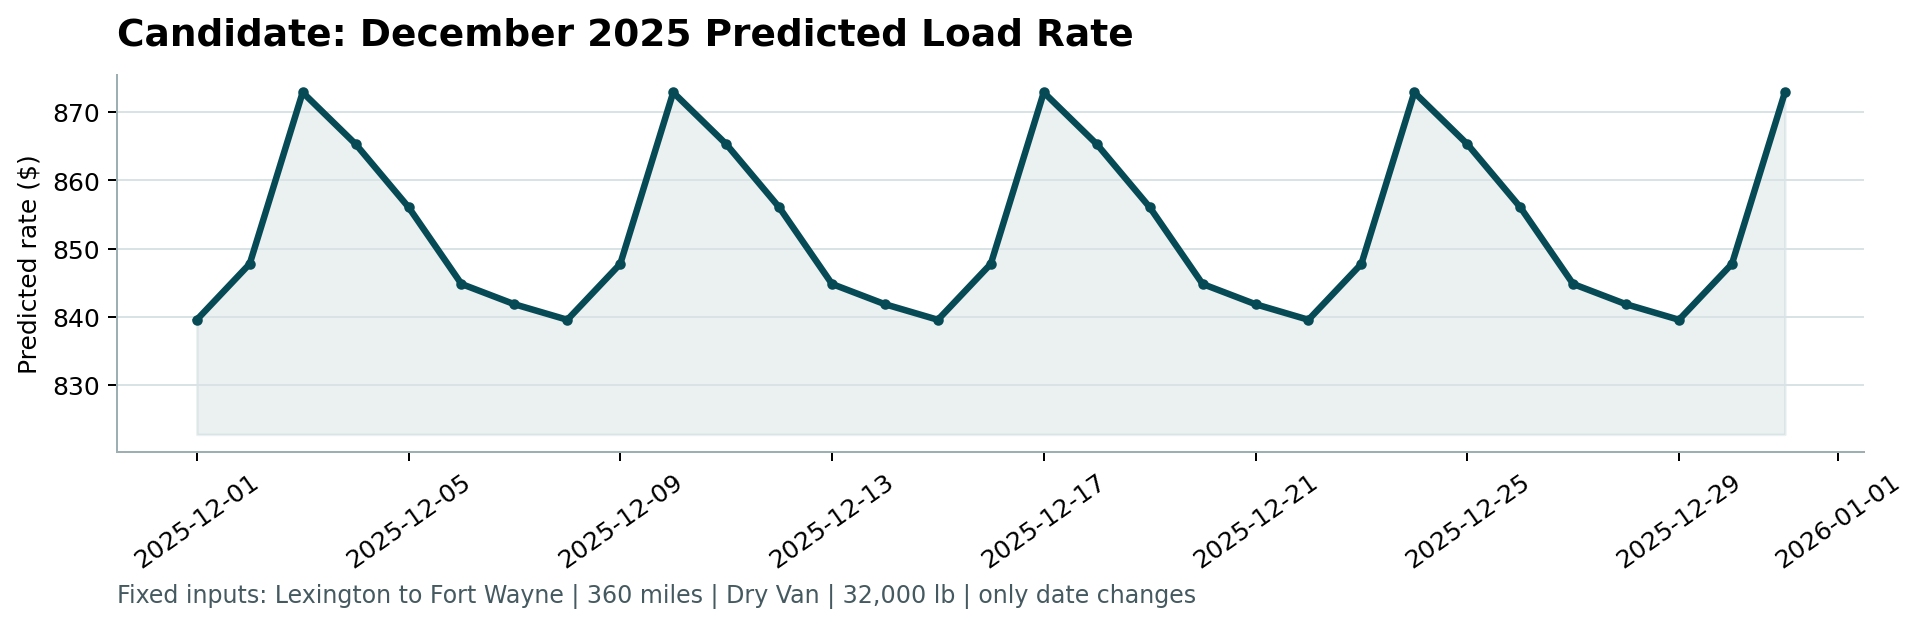

Submission CSV: /home/ajeet/Downloads/Assigment/freight_submission/notebook_results/validation_predictions.csv
December chart: /home/ajeet/Downloads/Assigment/freight_submission/notebook_results/scorer_results/candidate_december.png


In [16]:
scorer_dir = RUN_DIR / 'scorer_results'
result = subprocess.run([sys.executable, str(PROJECT_ROOT / 'score.py'),
    '--predictions', str(submission_path), '--december-predictions', str(december_path),
    '--output-dir', str(scorer_dir)], check=True, capture_output=True, text=True)
print(result.stdout)
(RUN_DIR / 'verification.txt').write_text(result.stdout)
display(Image(filename=str(scorer_dir / 'candidate_december.png')))
print('Submission CSV:', submission_path)
print('December chart:', scorer_dir / 'candidate_december.png')


## Interpretation and submission notes
- Weekly repetition in the chart is expected: route, distance, equipment, weight, and coordinates are fixed, and **weekday is the only varying model feature**. This is not a learned December trend or holiday surcharge.
- The selected core recipe achieved approximately **$110.39 MAE, $631.00 RMSE, 4.61% WAPE, and −$24.27 bias** in the later-period comparison. That period influenced selection; true final validation accuracy is unknown.
- The earlier market/scaled-MAE winner achieved approximately $115.27 MAE on March–August, but weakened on September–October. Results from these different periods must not be compared as if they were the same evaluation set.
- The concise notebook retains the key evidence and runnable final path. Full alternative-model training/debugging remains in `freight_rate_prediction.ipynb`; recorded metrics and predictions remain in `outputs/`. The saved-model path needs no GPU.
- Submit the checked `validation_predictions.csv`, existing `freight_rate_report.pdf`, accessible repository, and your Loom recording. The PDF describes the same archived model and chart. This notebook does not regenerate the PDF or replace the original submission files.
